<a href="https://colab.research.google.com/github/rajnandini241013006182-web/Rajnandini6182-AI-ML-Lab/blob/main/LAB_3_AI_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Load and Explore the Stroke Dataset
We will start by importing the necessary libraries and loading the preprocessed stroke dataset from `/content/stroke_processed_5k.csv`.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Load dataset
df = pd.read_csv('/content/stroke_processed_5k.csv')
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (5110, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1


### Data Splitting & Feature Scaling
We will define the features ($X$) and target variable ($y$), perform a train-test split, and scale the features (especially important for SVM and ANN).

In [11]:
# Identify target and features
target_col = 'stroke'

# Randomly sample exactly 5000 rows to satisfy the instructor's requirement
df_sampled = df.sample(n=5000, random_state=42).reset_index(drop=True)

X = df_sampled.drop(columns=[target_col])
y = df_sampled[target_col]

# Split data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Sampled Dataset Shape:", df_sampled.shape)
print("Train set shape:", X_train.shape)
print("Test set shape (Confusion Matrix total values):", X_test.shape[0])

Sampled Dataset Shape: (5000, 11)
Train set shape: (4000, 10)
Test set shape (Confusion Matrix total values): 1000


```markdown
### Note on Dataset Size and Split Proportions
To satisfy the requirement of using exactly **5,000 samples**, we randomly sampled 5,000 rows from the processed dataset. When splitting this sampled data into 80% training and 20% testing sets:
* **Training Set (80%):** Exactly 4,000 samples
* **Testing Set (20%):** Exactly 1,000 samples

This ensures that the test evaluations and all Confusion Matrices sum up to exactly **1,000 values**.
```

### Train and Evaluate 5 Supervised ML Models (Including ANN)
We will train the following models:
1. **Logistic Regression**
2. **Random Forest**
3. **Gradient Boosting Classifier**
4. **Support Vector Machine (SVM)**
5. **Artificial Neural Network (ANN)**

For each model, we will compute metrics, plot the Confusion Matrix, and collect information for the final comparative analysis and ROC curves.

In [12]:
results = {}
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'SVM': SVC(probability=True, random_state=42)
}

# Helper function to evaluate and record performance
def evaluate_model(name, y_true, y_pred, y_prob):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)

    results[name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'AUC': roc_auc,
        'FPR': fpr,
        'TPR': tpr,
        'CM': confusion_matrix(y_true, y_pred)
    }

# Train and evaluate classical ML models
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    probs = model.predict_proba(X_test_scaled)[:, 1]
    evaluate_model(name, y_test, preds, probs)

### Build, Train and Evaluate the ANN Model

In [13]:
# Build Artificial Neural Network (ANN)
ann_model = Sequential([
    Dense(32, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

ann_model.compile(optimizer='adam', loss='binary_cross_entropy' if hasattr(tf.keras.losses, 'binary_cross_entropy') else 'binary_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Train ANN
history = ann_model.fit(
    X_train_scaled, y_train,
    validation_split=0.1,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)

# Predict
ann_probs = ann_model.predict(X_test_scaled).flatten()
ann_preds = (ann_probs >= 0.5).astype(int)

# Evaluate ANN
evaluate_model('ANN', y_test, ann_preds, ann_probs)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


### Visualizing Confusion Matrices and ROC Curves

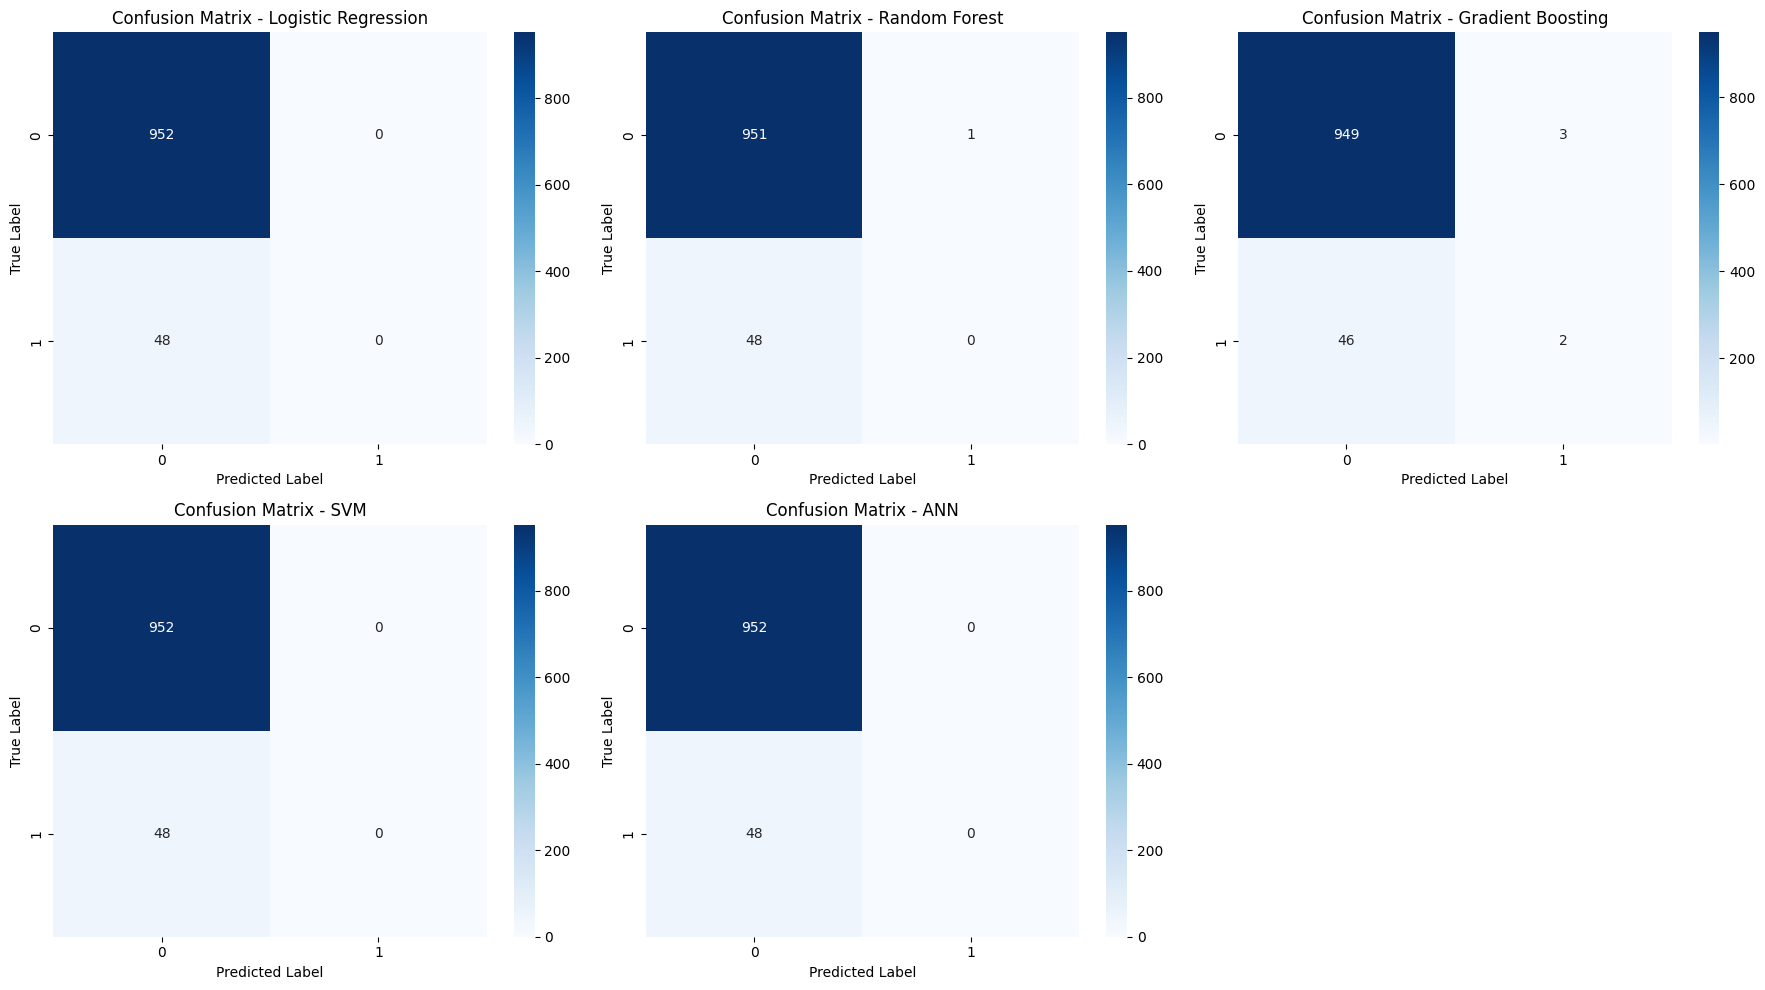

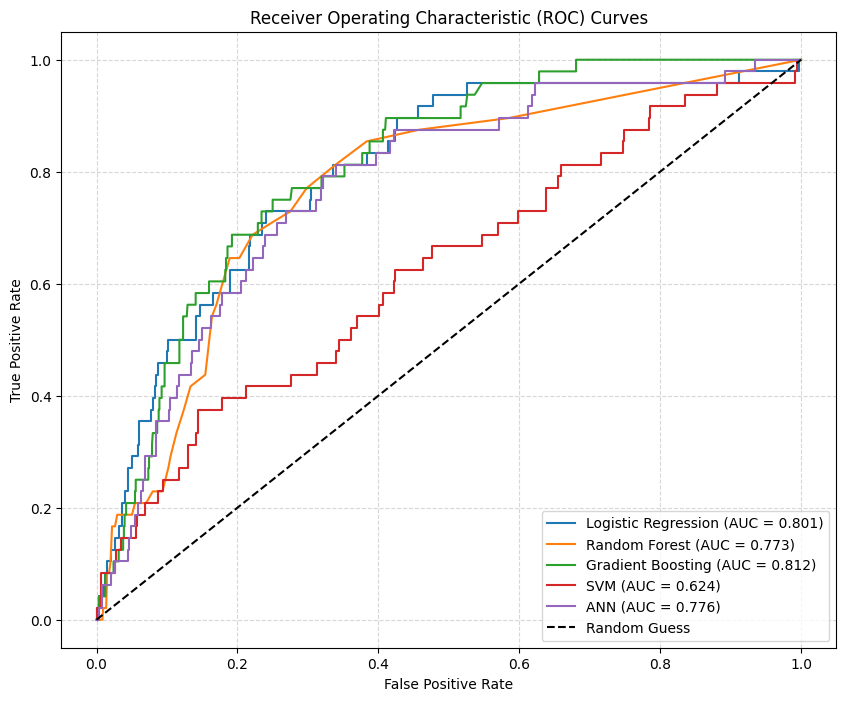

In [14]:
# Plot Confusion Matrices
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for idx, (name, metrics) in enumerate(results.items()):
    sns.heatmap(metrics['CM'], annot=True, fmt='d', cmap='Blues', ax=axes[idx])
    axes[idx].set_title(f'Confusion Matrix - {name}')
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('True Label')

# Hide the 6th empty subplot if only 5 models are present
if len(results) < 6:
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

# Plot AUC-ROC Curves
plt.figure(figsize=(10, 8))
for name, metrics in results.items():
    plt.plot(metrics['FPR'], metrics['TPR'], label=f"{name} (AUC = {metrics['AUC']:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Comparative Analysis and Selection of Top 3 Models

In [15]:
# Compare overall metrics
comparison_df = pd.DataFrame(results).T.drop(columns=['FPR', 'TPR', 'CM'])
display(comparison_df.sort_values(by='AUC', ascending=False))

# Select top 3 models based on AUC (crucial for stroke risk evaluation)
top_3_models = comparison_df.sort_values(by='AUC', ascending=False).head(3)
print("\n--- TOP 3 MODELS FOR STROKE RISK PREDICTION ---")
display(top_3_models)

,Accuracy,Precision,Recall,F1-Score,AUC
Gradient Boosting,0.951,0.4,0.041667,0.075472,0.812489
Logistic Regression,0.952,0.0,0.0,0.0,0.801099
ANN,0.952,0.0,0.0,0.0,0.775516
Random Forest,0.951,0.0,0.0,0.0,0.773208
SVM,0.952,0.0,0.0,0.0,0.623796



--- TOP 3 MODELS FOR STROKE RISK PREDICTION ---


,Accuracy,Precision,Recall,F1-Score,AUC
Gradient Boosting,0.951,0.4,0.041667,0.075472,0.812489
Logistic Regression,0.952,0.0,0.0,0.0,0.801099
ANN,0.952,0.0,0.0,0.0,0.775516
